In [37]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter
import glob
from concurrent.futures import ProcessPoolExecutor
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util
from tb_loader import load_file
from scipy.stats import ttest_ind, false_discovery_control

In [ ]:
IMPORTANT_STATS_NAMES = {
    "reward/mean": "Reward per timestep",
    "observation/progress_per_second": "Progress per second",
    "observation/forward_velocity": "Forward velocity",
    "collision/per_progress_metres": "Collisions per progress metre",
    "collision/per_episode": "Collisions per episode",
    "collision/per_step": "Collisions per step",
    "observation/progress_metres": "Progress per episode",
}

IMPORTANT_STATS = [key for key in IMPORTANT_STATS_NAMES.keys()]

MOST_IMPORTANT_STATS = [
    "observation/progress_metres",
    "collision/per_progress_metres"
]

In [39]:
def load_runs(logdir="runs", tags=None):
    tags = set(tags) if tags is not None else None
    jobs = []
    for model_name in os.listdir(logdir):
      for f in sorted(glob.glob(f"{logdir}/{model_name}/**/*tfevents*", recursive=True)):
          jobs.append((f, model_name, tags))

    with ProcessPoolExecutor() as pool:
        return pd.concat(pool.map(load_file, jobs), ignore_index=True)
                                 # all tags
if os.path.exists("results/tensorboard_data.pkl"):
    df = pd.read_pickle("results/tensorboard_data.pkl")
else:
    df = load_runs(tags=IMPORTANT_STATS)        # only these
    df.to_pickle("results/tensorboard_data.pkl")


In [40]:
data = df

In [41]:
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.sort_values("wall_time").drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [42]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_step"] / data_pivot["observation/progress_metres"]
data_pivot["observation/progress_per_second"] = data_pivot["observation/progress_metres"] * 25
data_pivot = data_pivot.reset_index()
data_pivot = data_pivot[~data_pivot["run_category"].str.startswith("rnn_")]
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second
0,0.0,all,s0,0.1,1.000000,0.001139,0.055985,0.002144,0.000996,0.531435,0.053597
1,0.0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,0.498418,0.048983
2,0.0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,0.471998,0.051725
3,0.0,all,s1,0.1,1.000000,0.001628,-0.025569,-0.000988,-0.002604,-1.646567,-0.024712
4,0.0,all,s1,0.3,1.000000,0.001058,-0.024407,-0.000804,-0.001854,-1.315935,-0.020099
...,...,...,...,...,...,...,...,...,...,...,...
184106,599.0,wheel_slip_rear_lateral,s4,0.3,0.901961,0.003743,2.121085,0.089808,0.085815,0.041683,2.245200
184107,599.0,wheel_slip_rear_lateral,s4,1,0.125000,0.000081,4.149317,0.174634,0.174548,0.000466,4.365861
184108,599.0,wheel_slip_rear_lateral,s5,0.1,0.708333,0.001383,0.874415,0.036265,0.034834,0.038149,0.906622
184109,599.0,wheel_slip_rear_lateral,s5,0.3,0.250000,0.000244,3.803875,0.161202,0.160941,0.001515,4.030049


In [43]:

RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

In [44]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50 = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50)
last_50_means = last_50.groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean()
last_50_means["collision/per_progress_metres"] = (
    last_50_means["collision/per_step"] / last_50_means["observation/progress_metres"]
)
last_50_means["observation/progress_per_second"] = last_50_means["observation/progress_metres"] * 25
last_50_means = last_50_means[IMPORTANT_STATS].reset_index()

/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


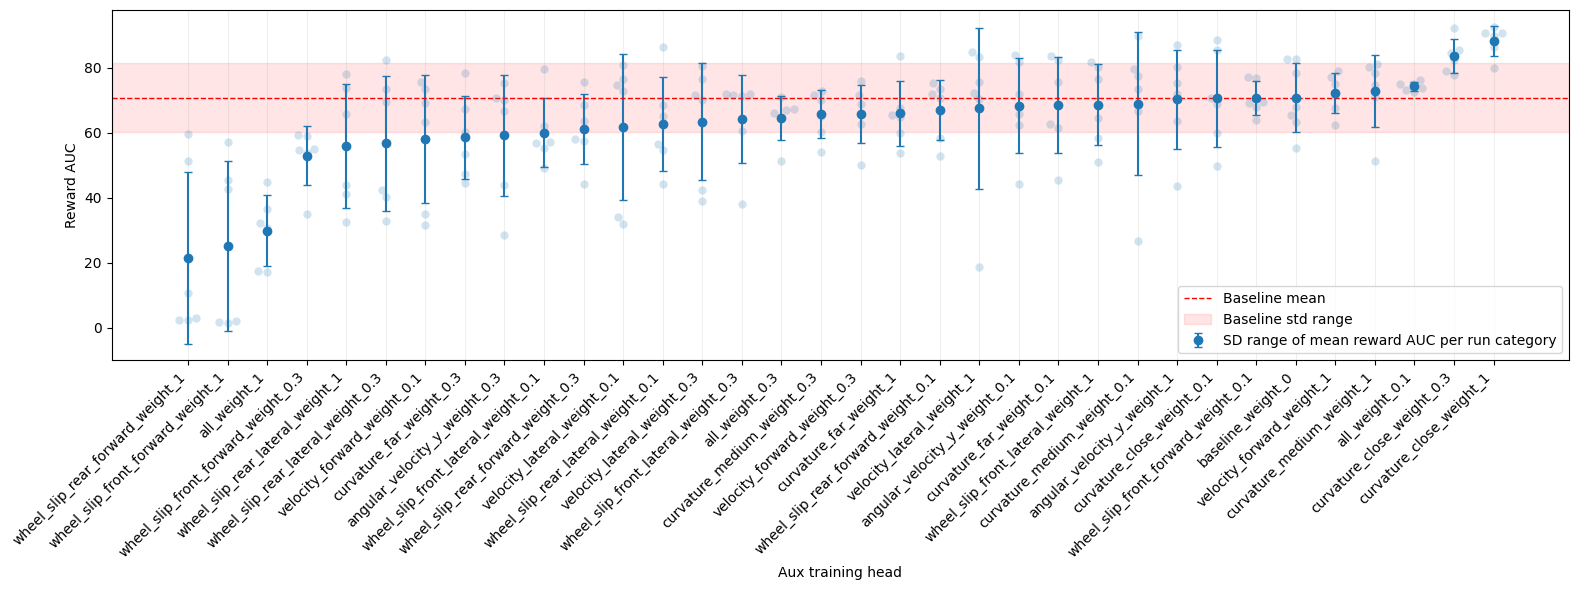

In [45]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std"]).reset_index().sort_values("mean")

base_mean = to_show[to_show["run_category"] == "baseline"][STAT].mean()
base_std = to_show_means[to_show_means["label"].str.contains("baseline")]["std"].mean()

order = to_show_means["label"].tolist()

plt.figure(figsize=(16, 6))

plt.errorbar(
    to_show_means["label"],
    to_show_means["mean"],
    yerr=to_show_means["std"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    x="label",
    y=STAT,
    order=order,
    legend=False,
    s=6,
    alpha=0.2
).set(xlabel="Aux training head", ylabel="Reward AUC")

sns.scatterplot(
    data=to_show_means,
    x="label",
    y="mean"
)

plt.grid(True, axis="x", alpha=0.2)

plt.axhline(base_mean, color="red", ls="--", lw=1, label="Baseline mean")
plt.axhspan(base_mean - base_std, base_mean + base_std,
            color="red", alpha=0.1, label="Baseline std range")

plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/auc_comparison.pdf", bbox_inches="tight")

In [46]:
baseline = last_50_means.loc[last_50_means["run_category"] == "baseline", IMPORTANT_STATS]

last_50_means_ttest_results = (
    last_50_means[last_50_means["run_category"] != "baseline"]
    .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
    .apply(lambda g: pd.Series(ttest_ind(g, baseline, equal_var=False).pvalue, index=IMPORTANT_STATS))
)

last_50_means_ttest_results = pd.DataFrame(false_discovery_control(last_50_means_ttest_results), columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)


In [ ]:
ALPHA = 0.5

to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)
baseline = to_show.loc["baseline"].squeeze()

to_show = to_show.div(baseline, axis=1) - 1

sig = (last_50_means_ttest_results < ALPHA).T.reindex(
    index=to_show.T.index, columns=to_show.T.columns, fill_value=False
)

plt.figure(figsize=(30, 4))

ax = sns.heatmap(
    to_show.T,
    annot=True,
    fmt="+.0%",
    cmap="RdBu",
    center=0,
    vmax=1.0,
    vmin=-1.0,
    cbar_kws={"format": FuncFormatter(lambda x, _: f"{x:+.0%}")},
)
ax.set(xlabel="Model name", ylabel="Metric")

for t in ax.texts:
    x, y = t.get_position()
    if sig.iat[int(y - 0.5), int(x - 0.5)]:
        t.set_fontweight("bold")
    else:
        t.set_alpha(0.3)

plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")

KeyError: 'reward/mean'

In [ ]:
to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().reset_index()
to_show

tag,run_category,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step,observation/progress_metres
0,all,0.1,0.168893,4.230164,3.935892,0.001640,0.243380,0.000278,0.169207
1,all,0.3,0.154685,3.884491,3.651143,0.004395,0.442131,0.000665,0.155380
2,all,1,0.101559,2.543456,2.376164,0.001730,0.150636,0.000165,0.101738
3,angular_velocity_y,0.1,0.118959,3.003655,2.813021,0.011408,0.577683,0.001143,0.120146
4,angular_velocity_y,0.3,0.098827,2.507224,2.349139,0.055348,0.643899,0.001405,0.100289
5,angular_velocity_y,1,0.149309,3.755572,3.514263,0.007933,0.466330,0.000857,0.150223
6,baseline,0,0.164709,4.132194,3.848117,0.003369,0.362828,0.000537,0.165288
7,curvature_close,0.1,0.147061,3.703341,3.461313,0.007845,0.460183,0.001012,0.148134
8,curvature_close,0.3,0.176422,4.419576,4.108107,0.001919,0.281761,0.000334,0.176783
9,curvature_close,1,0.186526,4.669992,4.332520,0.001288,0.209197,0.000240,0.186800


In [ ]:
last_50_means[last_50_means["run_category"] == "baseline"][IMPORTANT_STATS].std()

tag
reward/mean                        0.019794
observation/progress_per_second    0.491426
observation/forward_velocity       0.424072
collision/per_progress_metres      0.002793
collision/per_episode              0.163525
collision/per_step                 0.000443
observation/progress_metres        0.019657
dtype: float64

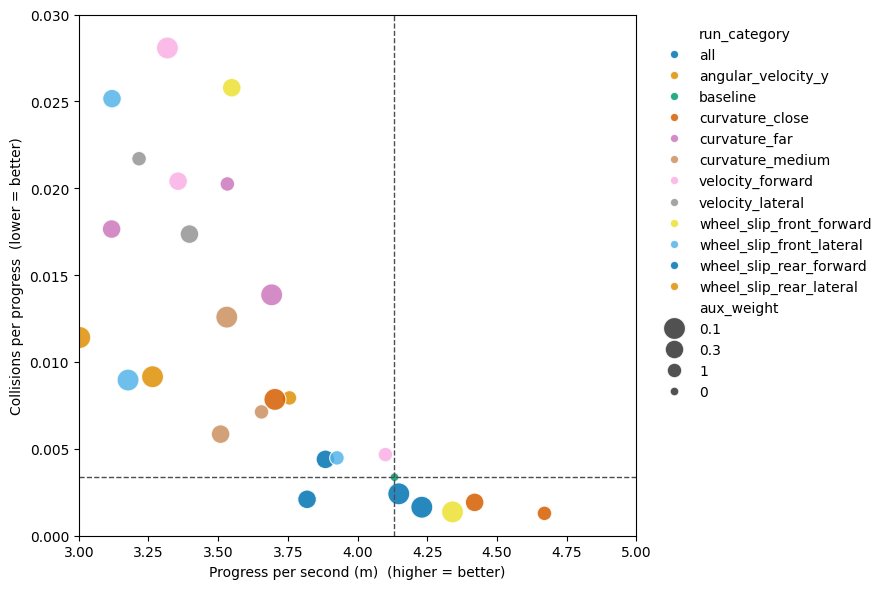

In [ ]:
x_col = "observation/progress_per_second"
y_col = "collision/per_progress_metres"

baseline = to_show[to_show["run_category"] == "baseline"]
bx, by = baseline[x_col].mean(), baseline[y_col].mean()

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=to_show,
    x=x_col,
    y=y_col,
    hue="run_category",
    size="aux_weight",
    sizes=(40, 250),
    palette="colorblind",
    alpha=0.85,
    edgecolor="white",
    legend="full",
    ax=ax,
).set()

# Baseline reference crosshair (dark grey so it doesn't clash with the palette)
ax.axhline(by, color="0.3", ls="--", lw=1)
ax.axvline(bx, color="0.3", ls="--", lw=1)
ax.annotate("baseline mean", (0.2, by), xytext=(-4, 5),
            textcoords="offset points", ha="right", fontsize=9, color="0.3")

ax.set(
    xlim=(3, 5),
    ylim=(0, 0.03),
    xlabel="Progress per second (m)  (higher = better)",
    ylabel="Collisions per progress  (lower = better)",
)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/progress_vs_collision.pdf", bbox_inches="tight")